In [1]:
%gui asyncio

In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
import tifffile

In [4]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000].astype(np.float32)

In [5]:
movie -= movie.mean(axis=0)

In [6]:
movie.shape

(10000, 512, 512)

In [7]:
%matplotlib inline

In [8]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [9]:
iw_movie.window_funcs = {"t": (np.mean, 7)}

In [10]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [11]:
rs.selection = (162, 268, 178, 288)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
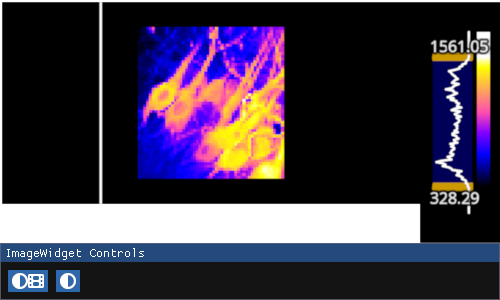

In [12]:
rows, cols = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

In [52]:
from ipywidgets import IntSlider, VBox

In [54]:
iw_p = fpl.ImageWidget(sub.std(axis=0), cmap="viridis")

slider_p = IntSlider(value=90, min=0, max=99, description="percentile: ")

def update_percentile(change):
    val = change["new"]
    g = iw_p.managed_graphics[0]
    g.vmin = np.percentile(g.data[:], val)

slider_p.observe(update_percentile, "value")

VBox([iw_p.show(), slider_p])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [14]:
sub.shape

(10000, 55, 53)

In [15]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(2915, 10000)

In [16]:
B = series @ series.T

In [17]:
B.min()

np.float32(-4443763700.0)

In [18]:
B[B < 0] = 0

In [53]:
B = np.abs((B + B.T) / 2)

In [19]:
B

array([[1.0777370e+09, 0.0000000e+00, 1.9305882e+07, ..., 0.0000000e+00,
        6.7902616e+07, 5.4287008e+07],
       [0.0000000e+00, 1.5066071e+09, 0.0000000e+00, ..., 5.1178580e+07,
        3.7553780e+07, 0.0000000e+00],
       [1.9305882e+07, 0.0000000e+00, 1.7662913e+09, ..., 0.0000000e+00,
        3.0260784e+07, 1.2341512e+07],
       ...,
       [0.0000000e+00, 5.1178580e+07, 0.0000000e+00, ..., 2.1643506e+10,
        6.9571692e+09, 2.3501711e+09],
       [6.7902616e+07, 3.7553780e+07, 3.0260784e+07, ..., 6.9571692e+09,
        1.7786534e+10, 2.3171540e+09],
       [5.4287008e+07, 0.0000000e+00, 1.2341512e+07, ..., 2.3501711e+09,
        2.3171540e+09, 1.0474275e+10]], dtype=float32)

In [20]:
B.shape

(2915, 2915)

In [21]:
B.min(), B.max()

(np.float32(0.0), np.float32(24368667000.0))

In [22]:
d = 1.0 / np.sum(B.astype(np.float64), axis=0)

In [23]:
a = np.diag(d) @ B

RFBOutputContext()

JupyterWgpuCanvas()
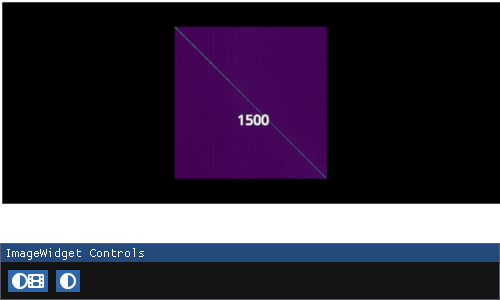

In [24]:
iw_s = fpl.ImageWidget(a, cmap="viridis", histogram_widget=False)
iw_s.show()

In [25]:
a.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [26]:
import pygpcca as gp

In [27]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

In [28]:
mc = gpcca.minChi(10, 30)

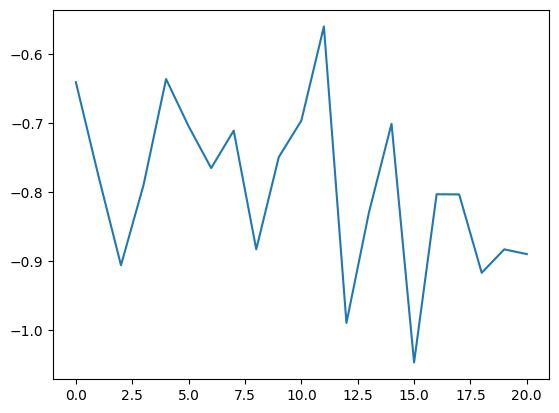

In [29]:
plt.plot(mc)

In [30]:
mc

[np.float64(-0.6411254039865187),
 np.float64(-0.7767280916284404),
 np.float64(-0.906097372943906),
 np.float64(-0.7900432622982202),
 np.float64(-0.636526335132797),
 np.float64(-0.7049427522132701),
 np.float64(-0.7654854467350058),
 np.float64(-0.7112175670584373),
 np.float64(-0.8830291508652727),
 np.float64(-0.7494780583554932),
 np.float64(-0.6967735185070436),
 np.float64(-0.5604744680982049),
 np.float64(-0.9896038995544808),
 np.float64(-0.8293860621944272),
 np.float64(-0.7012897203689022),
 np.float64(-1.0468062600194423),
 np.float64(-0.8033165427721403),
 np.float64(-0.8035547925733242),
 np.float64(-0.9170566574262574),
 np.float64(-0.88303664922721),
 np.float64(-0.8899504533894762)]

In [31]:
np.argmax(mc)

np.int64(11)

In [32]:
%load_ext viztracer

In [35]:
%%time
gpcca.optimize({'m_min':21, 'm_max':22})

CPU times: user 1min 21s, sys: 52 ms, total: 1min 22s
Wall time: 1min 22s


GPCCA[n=2915, n_macrostates=21]

In [36]:
gpcca.memberships.shape

(2915, 21)

In [37]:
gpcca.crispness_values

array([0.06513687, 0.05624768])

In [38]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [39]:
from ipywidgets import HBox

In [40]:
from fastplotlib.ui import EdgeWindow
from imgui_bundle import imgui

In [41]:
sub.min()

np.float32(-5680.0845)

In [42]:
sub.max()

np.float32(7029.458)

In [43]:
sub -= sub.min()
sub /= sub.max()

sub.min, sub.max()

(<function ndarray.min>, np.float32(1.0))

In [44]:
labels /= labels.max()

In [45]:
images = [img.T for img in labels.T]

In [46]:
for img in images:
    img[img < np.percentile(img, 80)] = 0

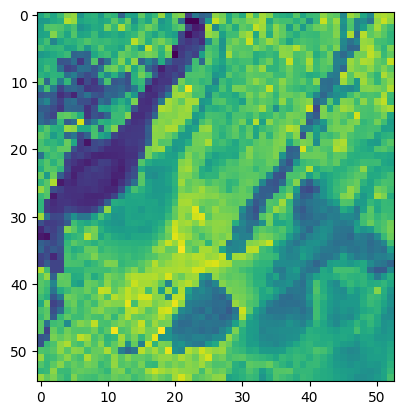

In [47]:
plt.imshow(sub.max(axis=0) - np.max(images, axis=0))

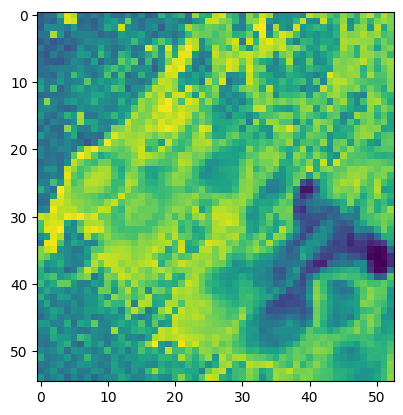

In [48]:
plt.imshow(np.max(sub, axis=0))

In [50]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(7):
    for j in range(3):
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")


fig_comps.show(), iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f0597ca27d0>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7f059706e050>)

In [92]:
iw_comps = fpl.ImageWidget(
    [img.T for img in labels.T], 
    names=[str(i) for i in range(labels.T.shape[0])], 
    histogram_widget=True, 
    figure_kwargs={"size": (1000, 1000), "canvas": "glfw"}, 
    cmap="viridis"
)

class PercentileUI(EdgeWindow):
    def __init__(self, figure, size, location, title, image_widget):
        super().__init__(figure=figure, size=size, location=location, title=title)
        # this UI will modify the line
        self.percentile = 80
        self._image_widget = image_widget
        self._percentile_changed()

    def _percentile_changed(self):
        for g in self._image_widget.managed_graphics:
            g.vmin = np.percentile(g.data[:], self.percentile)
            g.vmax = g.data[:].max()

    def update(self):
        changed, val = imgui.input_int("percentile: ", v=self.percentile, step=1)
        if changed:
            self.percentile = val
            self._percentile_changed()


# make GUI instance
percentile_gui = PercentileUI(
    iw_comps.figure,
    size=50,
    location="top",
    title="Perctile filter",
    image_widget=iw_comps
)

# add it to the figure
iw_comps.figure.add_gui(percentile_gui)
iw_comps.show()

for subplot in iw_comps.figure:
    subplot.toolbar = False

iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")

iw_comps_movies = fpl.ImageWidget([sub] * 13, cmap="gnuplot2", figure_kwargs={"canvas": "glfw", "size": (1200, 1000)})
for subplot in iw_comps_movies.figure:
    subplot.toolbar = False

def update_comps_movies(index: int):
    for g, mask in zip(iw_comps_movies.managed_graphics, iw_comps.managed_graphics):
        mask_data = mask.data[:].copy()
        mask_data[mask_data < mask.vmin] = 0
        
        g.data[:] *= mask_data

iw_comps_movies.add_event_handler(update_comps_movies)

iw_residuals = fpl.ImageWidget(sub, cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})

def update_residuals(frame):
    for mask in iw_comps.managed_graphics:
        mask_data = mask.data[:].copy()
        mask_data[mask_data < mask.vmin] = 0
        frame -= mask_data
    return frame

iw_residuals.frame_apply = {0: update_residuals}


iw_comps.show(), iw_movie.show(), iw_comps_movies.show(), iw_residuals.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.

(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fa9ac571450>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fa997f0b4d0>)

In [58]:
for i, _ in enumerate(labels.T):
    iw.managed_graphics[i].vmin = np.percentile(labels.T[i], 90)
    iw.managed_graphics[i].vmax = labels.T[i].max()

In [40]:
from ipywidgets import VBox

In [41]:
iw1 = fpl.ImageWidget(sub)
iw2 = fpl.ImageWidget(sub)

fig = fpl.Figure()

fig[0, 0].add_scatter(np.argwhere(labels.T[3] > 0.1), colors="g", sizes=10, alpha=0.4)
fig[0, 0].add_scatter(np.argwhere(labels.T[8] > 0.15), colors="r", sizes=10, alpha=0.4)

VBox([fig.show(), HBox([iw1.show(), iw2.show()])])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [42]:
fig.renderer.blend_mode = "weighted_plus"

In [43]:
iw1.current_index = {"t": 2288}
iw2.current_index = {"t": 3972}

In [44]:
gpcca.coarse_grained_transition_matrix.min()

np.float64(0.020271349682074485)

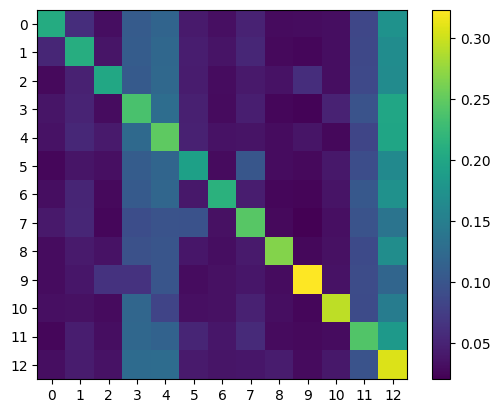

array([[0.20637425, 0.06001968, 0.03165649, 0.10761106, 0.11825953,
        0.04267813, 0.03252963, 0.049109  , 0.02971941, 0.03059786,
        0.03168177, 0.08495982, 0.17480337],
       [0.05240353, 0.20922359, 0.03782766, 0.10794889, 0.12097869,
        0.04418016, 0.03613014, 0.05282541, 0.02764983, 0.02597006,
        0.03198886, 0.08557976, 0.16729342],
       [0.02743826, 0.04856128, 0.20234833, 0.10591334, 0.12221456,
        0.04326885, 0.02993824, 0.04068926, 0.03529704, 0.05938069,
        0.03192726, 0.08707221, 0.16595067],
       [0.03696616, 0.05043668, 0.0297486 , 0.23677653, 0.12841798,
        0.04718043, 0.02904891, 0.04581267, 0.02570839, 0.02290876,
        0.04913828, 0.09801692, 0.19983969],
       [0.03528057, 0.05413678, 0.04159435, 0.12364881, 0.24827496,
        0.04760441, 0.03541237, 0.03676327, 0.03012524, 0.03776509,
        0.02658075, 0.08415478, 0.19865862],
       [0.02595015, 0.03712791, 0.03272326, 0.10847392, 0.11867696,
        0.19247629, 0.02952

In [45]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [51]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([], dtype=float64)

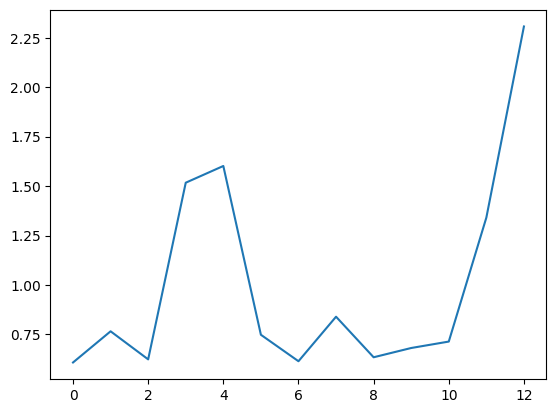

In [52]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))